# Llenado de un molde con la aproximación de Hele-Shaw

En inyección, la mayoría de las piezas son **delgadas**: el espesor $h$ es mucho menor que las demás dimensiones. Entonces el fundido avanza por el
plano medio de la pieza y, en cada punto, el flujo a través del espesor es como el de un canal entre dos placas (**Hele-Shaw**). En vez de resolver
el flujo en 3D, basta con la **planta** de la pieza, una malla 2D, con el espesor como dato. Es el método de los programas de inyección en modo
*midplane*.

Este cuaderno usa el módulo `Source/Physics/HeleShaw.py` para llenar una **placa con un inserto**. El frente rodea el inserto y se vuelve a juntar
detrás de él: ahí se forma una **línea de soldadura**.

## Las ecuaciones

Por unidad de área, el espesor deja pasar el caudal $\mathbf{q} = -S\,\nabla p$, con la **fluidez del espesor**

$$S = \int_{-h/2}^{h/2} \frac{z^2}{\eta(\dot\gamma(z))}\,dz .$$

El esfuerzo cortante crece linealmente desde el plano medio, $\tau(z) = z\,|\nabla p|$. En cada capa, la tasa de corte cumple
$\dot\gamma\,\eta(\dot\gamma) = z\,|\nabla p|$. Para un fluido newtoniano, $S = h^3/(12\eta)$. Para un fundido que adelgaza, $S$ crece con
$|\nabla p|$: se integra con capas de Gauss–Legendre y se tabula una vez por espesor.

En el fundido, la presión cumple $\nabla\cdot(S\,\nabla p) = 0$. Es una ecuación no lineal en un material que adelgaza, y se resuelve por Newton.

**El frente avanza por volúmenes de control** (método FAN, Wang y Hieber):

- Cada nodo tiene un volumen $V_i = \int N_i\,h\,dA$ y un **factor de llenado** $f_i \in [0, 1]$.
- La presión se resuelve en los nodos llenos, con $p = 0$ en los nodos del frente. El aire sale libremente por un venteo.
- La reacción del sistema en esos nodos es el caudal que reciben: $V_i\,df_i/dt = R_i$.
- Cada paso dura lo que tarda en llenarse el siguiente nodo.

Así **la masa se conserva exactamente**: la suma de las reacciones es el caudal inyectado.

Validación (`Test/test_hele_shaw.py`):

| Caso | Resultado |
|---|---|
| Tira a caudal constante | masa frente a $Qt$ a $10^{-14}$; presión de entrada de orden 1 (+0.78 % y +0.39 % al refinar) |
| Disco con entrada central | frente a un volumen de control del radio exacto; presión de entrada a −0.13 % (1 mm) y −0.01 % (0.5 mm) |
| Ley de potencia $n = 0.35$ | lo mismo: +0.14 % en el disco |

En esta etapa el llenado es **isotermo**: falta la temperatura a través del espesor, con el molde frío y la capa congelada.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib import animation
import gmsh

from Source.Pre_processing.Mesh import Mesh
from Source.Physics.HeleShaw import HeleShawFilling
from Source.Physics.Rheology import CrossWLF, Cross

Lx, Ly, h = 0.10, 0.06, 2e-3            # placa de 100 x 60 mm y 2 mm de espesor
xc, yc, rc = 0.05, 0.03, 0.008          # inserto circular de 8 mm de radio en el centro
Q = 2e-5                                # caudal de inyeccion [m3/s] = 20 cm3/s
T_MELT = 230.0                          # temperatura del fundido [C] (isotermo)
SIZE = 2e-3                             # tamano de elemento [m]

## El material

Es el **POLYFORT FPP 30 GFC K1079** (PP con 30 % de fibra de vidrio), con su ley Cross–WLF ajustada a la curva de viscosidad de la ficha técnica
(`Fitting.fit_cross_wlf`, error rms 0.12 %), evaluada a 230 °C. `gamma_min` evita que la derivada de Cross se haga infinita en reposo.

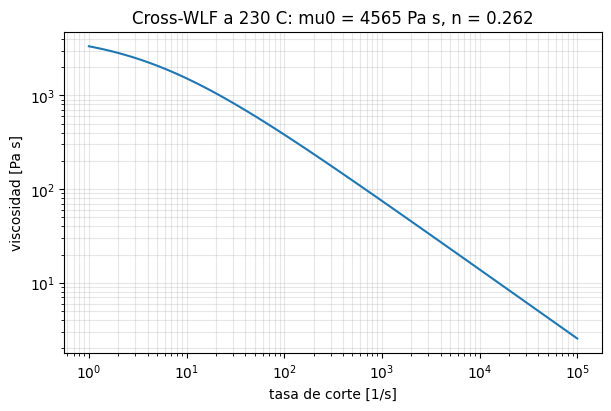

In [2]:
cross_wlf = CrossWLF(n=0.2619, tau_star=1.778e4, D1=4.378e17, D2=266.7, A1=39.22, A2=51.6)
mu0 = float(cross_wlf.zero_shear(T_MELT))
law = Cross(mu0, cross_wlf.tau_star, cross_wlf.n, gamma_min=1e-2)

rates = np.logspace(0, 5, 100)
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.loglog(rates, np.asarray(law(rates ** 2, T_MELT)), '-')
ax.set_xlabel('tasa de corte [1/s]'); ax.set_ylabel('viscosidad [Pa s]'); ax.grid(True, which='both', alpha=0.3)
ax.set_title(f'Cross-WLF a {T_MELT:.0f} C: mu0 = {mu0:.0f} Pa s, n = {cross_wlf.n:.3f}')
plt.show()

## La malla de la planta

Triángulos lineales: los volúmenes de control necesitan pesos positivos. La **entrada** es un tramo de 10 mm en el borde izquierdo.

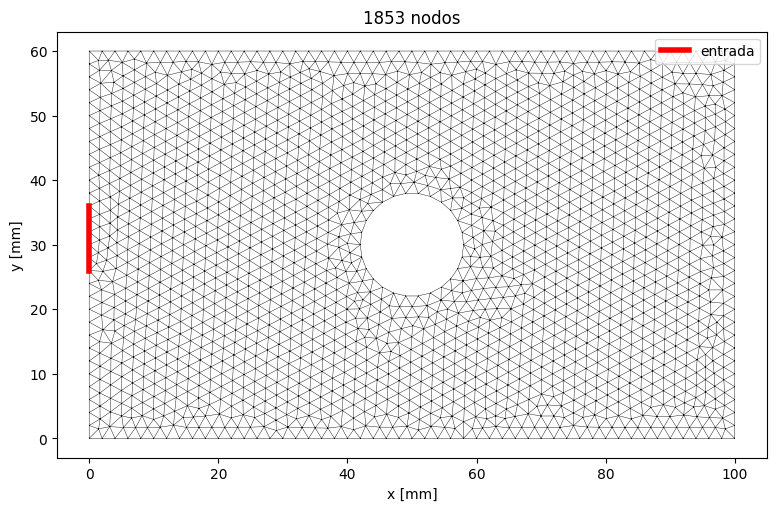

In [3]:
gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)
try:
    occ = gmsh.model.occ
    occ.cut([(2, occ.addRectangle(0, 0, 0, Lx, Ly))], [(2, occ.addDisk(xc, yc, 0, rc, rc))])
    occ.synchronize()
    gmsh.option.setNumber('Mesh.MeshSizeMax', SIZE)
    gmsh.model.mesh.generate(2)
    mesh = Mesh.from_gmsh_model()
finally:
    gmsh.finalize()

xy = np.array([n.coor[:2] for n in mesh.NL])
tri = mtri.Triangulation(xy[:, 0] * 1e3, xy[:, 1] * 1e3, mesh.plot_triangles())
gate = mesh.boundary_edges(lambda x, y: x < 1e-9 and abs(y - Ly / 2) < 0.005)
gate_nodes = np.unique(np.ravel(gate))

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.triplot(tri, lw=0.3, color='k')
ax.plot(xy[gate_nodes, 0] * 1e3, xy[gate_nodes, 1] * 1e3, 'r-', lw=4, label='entrada')
ax.set_aspect('equal'); ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.legend(loc='upper right')
ax.set_title(f'{len(xy)} nodos')
plt.show()

## El llenado

`fill()` avanza nodo a nodo hasta llenar la cavidad. `on_step` toma instantáneas del factor de llenado y de la presión para la animación.

In [4]:
fill = HeleShawFilling(mesh, h, law)
fill.addGate(gate, Q)

frames, last = [], [0.0]
def snapshot(f):
    if f.time - last[0] >= 0.012 or np.all(f.fill_factor >= 1):          # unas 50 imagenes en todo el llenado
        frames.append((f.time, f.fill_factor.copy(), f.p.copy()))
        last[0] = f.time

start = time.perf_counter()
fill.fill(progress=True, every=300, on_step=snapshot)
history = np.array(fill.history)
print(f"\nLlenado en {fill.time:.3f} s de inyeccion ({time.perf_counter() - start:.0f} s de calculo); presion de entrada al final "
      f"{history[-1, 2] / 1e6:.2f} MPa; volumen {fill.melt_volume() * 1e6:.3f} cm3 = Q t {Q * fill.time * 1e6:.3f} cm3")

   llenado: paso 300, t = 0.1026 s, 16.5 % de los nodos llenos, p de entrada 1.964 MPa, 6 it. de Newton (15 s)
   llenado: paso 600, t = 0.196 s, 32.7 % de los nodos llenos, p de entrada 2.942 MPa, 6 it. de Newton (31 s)
   llenado: paso 900, t = 0.2869 s, 48.9 % de los nodos llenos, p de entrada 4.259 MPa, 6 it. de Newton (47 s)
   llenado: paso 1200, t = 0.3799 s, 65.1 % de los nodos llenos, p de entrada 5.578 MPa, 6 it. de Newton (65 s)
   llenado: paso 1500, t = 0.4756 s, 81.3 % de los nodos llenos, p de entrada 6.754 MPa, 6 it. de Newton (85 s)
   llenado: paso 1800, t = 0.5737 s, 97.5 % de los nodos llenos, p de entrada 7.918 MPa, 5 it. de Newton (106 s)

Llenado en 0.579 s de inyeccion (109 s de calculo); presion de entrada al final 8.89 MPa; volumen 11.602 cm3 = Q t 11.583 cm3


## Isócronas: dónde está el frente en cada instante

Cada línea une los puntos que se llenan a la vez. El frente sale radial de la entrada, se abre en el ancho de la placa, se divide en el inserto
y se junta detrás de él. Las flechas son la dirección de avance del frente, $\nabla t_\text{llenado}$: donde chocan de frente, en el eje detrás del
inserto, queda la **línea de soldadura**, una zona débil de la pieza.

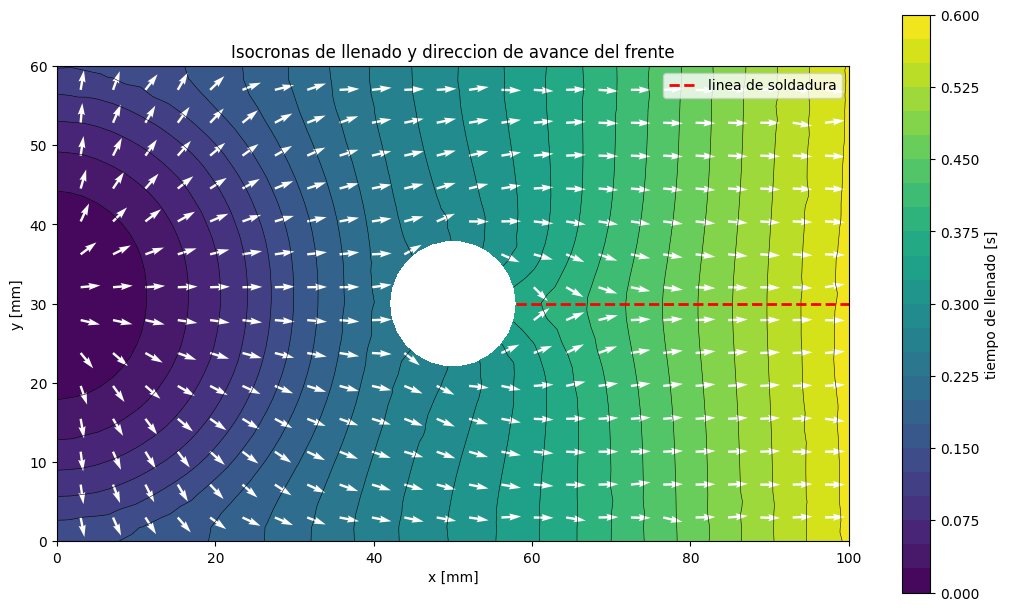

In [5]:
ft = fill.fill_time
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
c = ax.tricontourf(tri, ft, levels=24, cmap='viridis')
ax.tricontour(tri, ft, levels=24, colors='k', linewidths=0.4)
fig.colorbar(c, ax=ax, label='tiempo de llenado [s]')
# direccion del frente: el gradiente del tiempo de llenado, en una rejilla
gx, gy = np.meshgrid(np.linspace(3, 97, 24), np.linspace(3, 57, 14))
interp = mtri.LinearTriInterpolator(tri, ft)
dx, dy = interp.gradient(gx, gy)
norm = np.hypot(dx, dy)
ax.quiver(gx, gy, dx / norm, dy / norm, color='w', scale=40, width=0.003)
ax.plot([(xc + rc) * 1e3, Lx * 1e3], [yc * 1e3, yc * 1e3], 'r--', lw=2, label='linea de soldadura')
ax.set_aspect('equal'); ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.legend(loc='upper right')
ax.set_title('Isocronas de llenado y direccion de avance del frente')
plt.show()

## Presión

A la izquierda, la presión al final del llenado: cae de la entrada al último punto lleno. A la derecha, la presión de entrada frente al tiempo, que
crece a medida que aumenta el recorrido del fundido. Al dividirse en el inserto la pendiente cambia poco: hay sección de sobra a los lados.

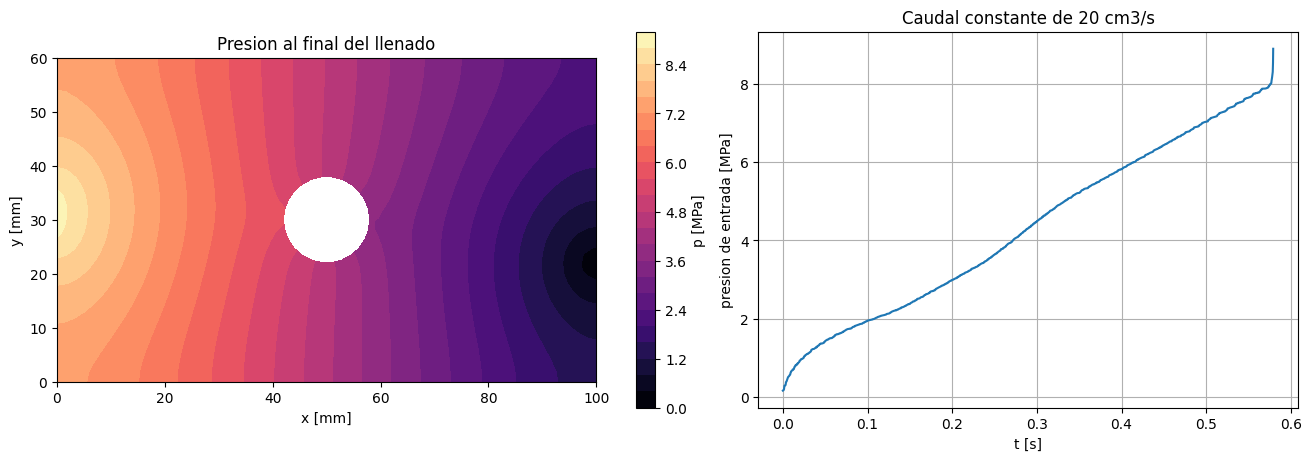

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
c = axes[0].tricontourf(tri, fill.p / 1e6, levels=24, cmap='magma')
fig.colorbar(c, ax=axes[0], label='p [MPa]')
axes[0].set_aspect('equal'); axes[0].set_xlabel('x [mm]'); axes[0].set_ylabel('y [mm]'); axes[0].set_title('Presion al final del llenado')
axes[1].plot(history[:, 0], history[:, 2] / 1e6, '-')
axes[1].set_xlabel('t [s]'); axes[1].set_ylabel('presion de entrada [MPa]'); axes[1].grid(True)
axes[1].set_title(f'Caudal constante de {Q * 1e6:.0f} cm3/s')
plt.show()

## Animación del llenado

El fundido se colorea por su presión, más oscuro cuanto más alta, y la cavidad vacía queda en gris. La línea negra es el frente. El escalonado
del frente es el de los volúmenes de control: se conoce a un elemento. La animación también se guarda como `llenado_placa.gif`.

In [7]:
from IPython.display import HTML

p_max = max(f[2].max() for f in frames) / 1e6
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)

def draw(k):
    ax.clear()
    t, f, p = frames[k]
    ax.tricontourf(tri, f, levels=[-0.1, 0.5], colors=['0.85'])                 # la cavidad vacia
    melt = np.where(f >= 0.5, p / 1e6, np.nan)
    ax.tricontourf(tri, np.nan_to_num(melt, nan=-1.0), levels=np.linspace(0, p_max, 21), cmap='Blues')
    ax.tricontour(tri, f, levels=[0.5], colors='k', linewidths=1.5)
    ax.add_patch(plt.Circle((xc * 1e3, yc * 1e3), rc * 1e3, color='0.6'))
    ax.set_xlim(0, Lx * 1e3); ax.set_ylim(0, Ly * 1e3); ax.set_aspect('equal')
    ax.set_title(f't = {t:.3f} s, {100 * np.mean(f >= 1):.0f} % lleno'); ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]')

movie = animation.FuncAnimation(fig, draw, frames=len(frames), interval=120)
movie.save('llenado_placa.gif', writer=animation.PillowWriter(fps=8))
plt.close(fig)
HTML(movie.to_jshtml())

## Notas y límites

- **Isotermo**: la viscosidad es la del fundido a 230 °C en todo el llenado. En una pieza real el molde frío forma una capa congelada que estrecha el
  canal y sube la presión. Esa es la siguiente etapa del módulo.
- **El frente se conoce a un volumen de control**: los mapas mejoran al refinar la malla (`SIZE`), a costa de más pasos, porque el llenado avanza
  nodo a nodo.
- **Sin empaque**: el fundido es incompresible. La compresibilidad con Tait ya existe en el flujo 2D (`Example_Packing.py`) y entrará en la
  etapa 3.
- El espesor puede variar en la planta: `HeleShawFilling(mesh, gap=lambda x, y: ..., ...)`.